### Tourality – Lösung Schritt für Schritt

*31. Bundeswettbewerb Informatik (2012/2013), 2. Runde, Aufgabe 3*

Tourality ist ein Strategiespiel und wird zu zweit auf einem Spielplan mit 20 × 20 Feldern gespielt. Jeder Spieler hat eine
Spielfigur; außerdem gibt es Chips und Hindernisse. Auf jedem Feld kann sich entweder eine Spielfigur, ein Hindernis oder ein Chip
befinden, oder es ist frei. Ein Standard-Spielplan hat 40 Chips und 40 Hindernisse. Die Hindernisse sind beliebig verteilt, aber so,
dass sie keine Bereiche komplett isolieren.

Die Spieler ziehen abwechselnd. In einem Spielzug kann die Spielfigur genau um ein Feld nach oben, unten, links oder rechts bewegt
werden oder stehen bleiben. Die Spielfigur darf sich nur auf Felder bewegen, die frei oder durch einen Chip belegt sind. Bewegt ein
Spieler seine Spielfigur auf ein Feld mit Chip, wird der Chip entfernt und der Spieler bekommt einen Punkt gutgeschrieben.

Ziel des Spiels ist, möglichst viele Punkte zu sammeln, also mehr Chips als der Gegenspieler zu ergattern.

Zu Beginn des Spiels befinden sich die Spielfiguren auf den Startpositionen s1 und s2 des Spielfelds. Der Spieler, dessen Figur auf
s1 steht, beginnt. Jedes Spiel hat zwei Runden, mit vertauschten Startpositionen, so dass jeder Spieler einmal beginnen darf.

**Aufgabe**

Schreibe eine „KI“ für Tourality: ein Programm, das einen Tourality-Spieler simuliert und im Spiel gegen andere Tourality-KIs
möglichst erfolgreich abschneidet. Deine KI wird schließlich in einem Turnier gegen die KIs anderer Teilnehmer antreten.

Die virtuellen Tourality-Spiele werden auf unserem Turnier-Server durchgeführt, der unter turnier.bundeswettbewerb-informatik.de
erreichbar ist und ab 2.1.2013 offiziell zur Verfügung steht. Dort findest du ausführliche technische Anleitungen. Insbesondere
gelten folgende Regeln:

- Dein Programm kann das gesamte Spielfeld „überblicken“, kennt also zu jeder Zeit die Positionen der Hindernisse, der Chips und
  beider Spielfiguren.
- Dein Programm teilt seine Spielzüge dem Turnier-Server einzeln mit.
- Dein Programm darf nur gültige Züge machen. Ein ungültiger Spielzug wird vom Turnier-Server ignoriert, wird also wie ein Zug ohne
  Bewegung behandelt.
- Dein Programm darf nicht zu lange „nachdenken“ und hat pro Zug nur eine bestimmte Anzahl von Zyklen zur Verfügung. Auch die
  insgesamt zur Verfügung stehende Rechenzeit ist begrenzt; sie wird in der Spielbeschreibung auf dem Server veröffentlicht. Ihr
  könnt davon ausgehen, dass sie sehr großzügig bemessen ist! Nach Ablauf dieser Zeit bleibt die Spielfigur deines Programms stehen,
  und das gegnerische Programm kann – im Rahmen seiner eigenen Rechenzeit – alle übrigen Chips abräumen.

Teste deine – Künstliche – Intelligenz!

Damit deine Bearbeitung dieser Aufgabe in der 2. Runde gewertet wird, musst du deine KI auf den Turnier-Server hochladen. Wenn deine
KI die anschließend durchgeführte grundlegende Prüfung besteht, wird sie für den Wettbewerb freigegeben.

Damit du einschätzen kannst, wie gut deine KI ist, kannst du sie nun gegen andere, bereits freigegebene KIs antreten lassen. Fordere
dazu über den Turnier-Server die KIs anderer Mitspieler heraus. Die Ergebnisse dieser Spiele fließen nicht in die Bewertung ein. Du
kannst nach und nach weitere, verbesserte KIs hochladen und auch sie ausprobieren.

*(Es folgen Hinweise zur Einsendung: Eine hochgeladene KI wird als „eingereicht“ markiert und nimmt an einem abschließenden Turnier
teil, dessen Ausgang in die Bewertung eingeht.)*

#### Beispieldaten

Zu dieser Aufgabe gibt es keine Beispieldaten, und den Turnierserver gibt es nicht mehr. Wir spielen deshalb unsere eigenen
Turniere. Dazu haben wir Dateien angelegt; jede Zeile ist eine Zeile des Spielplans, `#` ist ein Hindernis, `*` ein Chip, `.` ein
freies Feld, `1` und `2` sind die Startfelder s1 und s2.

In `beispieldaten/`:
- `standard1.txt` bis `standard4.txt`: Standard-Spielpläne mit 20 × 20 Feldern, 40 Chips und 40 Hindernissen, zufällig verteilt
  (wir erzeugen sie weiter unten selbst), ohne abgetrennte Bereiche.
- Sechs kleine Karten aus den Abbildungen der Lösungshinweise, die wir aus den Bildern abgelesen haben (die Bilder zeigen den
  Rahmen aus Hindernissen mit): `abb7a_umweg.txt` (Abb. 7a, ein Spieler allein), `abb7b_hinterher.txt` (Abb. 7b),
  `abb8a_warten.txt` und `abb8b_zugbegrenzung.txt` (Abb. 8), `abb9a_ordnung.txt` und `abb9b_sackgassen.txt` (Abb. 9; bei 9b haben wir
  die beiden Startfelder selbst gesetzt, das Bild zeigt keine Spieler). In den Bildern ist die Figur mit dem Kopf Spieler `1`, die
  rote Kugel Spieler `2`.

In `eigene_testdaten/` liegt `hinterher_lang.txt`, eine verlängerte Abb. 7b mit 8 Chips.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Breitensuche** auf einem Gitter: Sie findet von einem Feld aus die kürzesten Wege zu allen anderen Feldern. Weil wir die
  Abstände sehr oft brauchen, berechnen wir sie einmal für alle Paare von Feldern und speichern sie in einer **Abstandstabelle**.
- **Simulation:** Ein Programm spielt das Spiel Zug für Zug nach den Regeln. So können wir KIs gegeneinander antreten lassen.
- **Gierige Verfahren (Heuristiken):** „Geh zum nächsten Chip“ ist einfach und schnell, aber nicht immer gut.
- **Spielbaum und Minimax:** Bei einem Spiel zu zweit mit vollständiger Information kann man den besten Zug ausrechnen, indem man
  annimmt, dass der Gegner immer seinen besten Zug macht. Die Lösungshinweise schreiben das als
  **wert(S) = max (c − wert(S nach dem Zug))**: Was ich mit dem Zug bekomme (c = 1 für einen Chip), minus das, was der Gegner danach
  herausholen kann.
- **Dynamische Programmierung (Rückwärtsrechnung):** Den Wert aller Spielsituationen mit 1, 2, 3, … verbleibenden Zügen berechnen,
  jede Schicht aus der vorigen. Das geht nur auf kleinen Karten.
- **Kürzeste Sammeltour:** Alle Chips allein möglichst schnell einsammeln ist ein **Problem des Handlungsreisenden**; für kleine
  Karten lösen wir es mit Breitensuche über (Feld, übrige Chips), für 40 Chips mit MiniZinc.

**Nützliche Funktionen und Bibliotheken**
- `collections.deque` als Warteschlange für die Breitensuche (`append`, `popleft`).
- `frozenset`: eine Menge, die man nicht mehr ändern kann. Sie darf (anders als `set`) Teil eines Schlüssels in einem `dict` sein,
  z. B. `(feld1, feld2, frozenset(chips))`.
- `itertools.combinations(liste, k)` liefert alle Auswahlen von k Elementen, damit erzeugen wir alle Teilmengen der Chips.
- `random.Random(startzahl)`: ein eigener Zufallsgenerator, der mit derselben Startzahl immer dieselben Zahlen liefert.
- `matplotlib`: `imshow` zeichnet ein Bild aus Farbwerten (unser Spielplan), `plot` die Wege der Spieler.

## Die Idee in Worten

**Spielregeln festlegen.** Die Aufgabe lässt einiges offen. Wir nehmen an (wie in den Lösungshinweisen): Jeder Spieler hat pro Runde
höchstens **400 Züge**, eine Runde endet, wenn alle Chips weg sind oder beide ihre 400 Züge gemacht haben. Eine Figur darf nicht auf
das Feld der anderen Figur ziehen (es ist ja nicht frei). Ein ungültiger Zug zählt als Stehenbleiben. Gewertet wird die Summe der
Chips aus beiden Runden.

**Optimal spielen geht nicht.** Eine Spielsituation besteht aus beiden Positionen, den übrigen Chips und der Zahl der übrigen Züge.
Auf kleinen Karten können wir für jede Situation ausrechnen, wie viele Chips man gegen einen perfekten Gegner herausholt (Schritt 5).
Auf einem 20 × 20-Plan mit 40 Chips gibt es aber nach der Abschätzung der Lösungshinweise etwa 10⁸ · 2⁴⁰ Situationen. Wir brauchen
also Heuristiken.

**Vier KIs**, jede ein bisschen schlauer:
1. **zufall** zieht auf ein zufälliges erlaubtes Feld (zum Vergleich).
2. **nn** (*Nearest Neighbour*, nächster Nachbar) geht immer auf kürzestem Weg zum nächsten Chip. Sie achtet nicht auf den Gegner und
   läuft ihm deshalb oft hinterher.
3. **wettlauf** geht zum nächsten Chip, **den sie vor dem Gegner erreicht**. Chips, die der Gegner sowieso zuerst bekommt, lässt sie
   liegen.
4. **ziele** folgt dem **Chip-basierten Ansatz** der Lösungshinweise: Sie überlegt sich, welchen Chip sie als Nächstes ansteuert,
   und behält dieses Ziel, bis sie es erreicht hat oder der Gegner es weggeschnappt hat. Als Kandidaten nimmt sie nur Chips, auf deren
   kürzestem Weg kein anderer Chip liegt (die Menge **G** der Hinweise). Jeden Kandidaten bewertet sie mit einem schnell simulierten
   **Wettrennen**: Wie geht das Spiel aus, wenn ich zuerst diesen Chip hole und danach beide immer zum nächsten Chip laufen? Das ist
   die Bewertungsfunktion, die die Hinweise vorschlagen („das Ergebnis, welches zwei einfach zu berechnende KIs erbringen“).

Am Ende lassen wir alle KIs in einem **Turnier** gegeneinander antreten.

## Schritt 1: Spielplan lesen und zeichnen

Wir speichern einen Spielplan als `dict`: die Menge der freien Felder (alles außer Hindernissen, also auch Chips und Startfelder),
die Menge der Chips und die beiden Startfelder. Ein Feld ist ein Paar `(zeile, spalte)`. Wie in den Hinweisen vorgeschlagen,
legen wir einen **Rahmen aus Hindernissen** um den Plan, dann muss man am Rand nichts Besonderes prüfen. Zeile 0 und Spalte 0 sind
also Rahmen, die erste Zeile der Datei ist Zeile 1.

In [ ]:
from collections import deque
import itertools
import random
import matplotlib.pyplot as plt

SCHRITTE = [(-1, 0), (0, 1), (1, 0), (0, -1)]       # oben, rechts, unten, links


def plan_aus_zeilen(zeilen):
    """Macht aus den Zeilen eines Spielplans ein dict. Ringsum kommt ein Rahmen aus Hindernissen dazu."""
    breite = max(len(zeile) for zeile in zeilen)
    zeilen = ['#' * (breite + 2)] + ['#' + zeile.ljust(breite, '#') + '#' for zeile in zeilen] + ['#' * (breite + 2)]
    plan = {'zeilen': zeilen, 'frei': set(), 'chips': set(), 's1': None, 's2': None}
    for z in range(len(zeilen)):
        for s in range(len(zeilen[z])):
            zeichen = zeilen[z][s]
            if zeichen != '#':
                plan['frei'].add((z, s))
            if zeichen == '*':
                plan['chips'].add((z, s))
            if zeichen == '1':
                plan['s1'] = (z, s)
            if zeichen == '2':
                plan['s2'] = (z, s)
    plan['abstand'] = abstandstabelle(plan)       # Schritt 2
    return plan


def lies_plan(dateiname):
    with open(dateiname, encoding='utf-8') as datei:
        zeilen = [zeile.rstrip('\n') for zeile in datei if zeile.strip() != '']
    return plan_aus_zeilen(zeilen)


def nachbarn(plan, feld):
    """Die freien Nachbarfelder (oben, rechts, unten, links)."""
    z, s = feld
    ergebnis = []
    for dz, ds in SCHRITTE:
        if (z + dz, s + ds) in plan['frei']:
            ergebnis.append((z + dz, s + ds))
    return ergebnis

Zum Zeichnen bauen wir ein Bild aus Farbwerten (Rot, Grün, Blau zwischen 0 und 1): Hindernisse schwarz, Chips grün, freie Felder
hellgrau. Die Spieler sind farbige Kreise mit ihrer Nummer, ihre Wege (falls angegeben) farbige Linien.

In [ ]:
FARBE = {1: 'tab:blue', 2: 'tab:red'}


def zeichne(plan, ax, chips=None, positionen=None, wege=None, titel=''):
    """Zeichnet den Plan in das Diagramm ax. Ohne Angaben: Chips und Startfelder vom Anfang."""
    if chips is None:
        chips = plan['chips']
    if positionen is None:
        positionen = [plan['s1'], plan['s2']]
    bild = []
    for z in range(len(plan['zeilen'])):
        reihe = []
        for s in range(len(plan['zeilen'][0])):
            if (z, s) not in plan['frei']:
                reihe.append((0.1, 0.1, 0.1))
            elif (z, s) in chips:
                reihe.append((0.2, 0.8, 0.2))
            else:
                reihe.append((0.85, 0.85, 0.85))
        bild.append(reihe)
    ax.imshow(bild)
    if wege is not None:
        for nr in [1, 2]:
            if wege[nr - 1]:
                ax.plot([s for z, s in wege[nr - 1]], [z for z, s in wege[nr - 1]], color=FARBE[nr], linewidth=2, alpha=0.7)
    for nr in [1, 2]:
        feld = positionen[nr - 1]
        if feld is not None:
            ax.add_patch(plt.Circle((feld[1], feld[0]), 0.4, color=FARBE[nr]))
            ax.text(feld[1], feld[0], str(nr), color='white', ha='center', va='center', fontsize=8, fontweight='bold')
    ax.set_title(titel, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

Bevor wir die Pläne lesen, brauchen wir noch die Abstandstabelle aus Schritt 2 (`plan_aus_zeilen` ruft sie auf).

## Schritt 2: Abstände mit Breitensuche

Die Breitensuche beginnt auf einem Feld mit Abstand 0. Sie nimmt immer das Feld vorne aus der Warteschlange und gibt allen noch
nicht besuchten Nachbarn den Abstand plus 1. So bekommt jedes Feld seinen kürzesten Abstand. Mit `gesperrt` kann man ein Feld
verbieten (das Feld des Gegners).

Ein 20 × 20-Plan hat 360 freie Felder (400 minus 40 Hindernisse). Eine Breitensuche besucht jedes Feld einmal, für alle Startfelder
zusammen sind das 360 · 360 ≈ 130 000 Schritte. Das geht in Bruchteilen einer Sekunde, und danach kostet jeder Abstand nur noch einen
Blick in die Tabelle: `plan['abstand'][a][b]`. Die Tabelle beachtet die Hindernisse, aber nicht die Spielfiguren.

In [ ]:
def abstaende(plan, start, gesperrt=None):
    """Breitensuche: dict Feld -> Länge des kürzesten Weges von start."""
    abstand = {start: 0}
    schlange = deque([start])
    while schlange:
        feld = schlange.popleft()
        for n in nachbarn(plan, feld):
            if n not in abstand and n != gesperrt:
                abstand[n] = abstand[feld] + 1
                schlange.append(n)
    return abstand


def abstandstabelle(plan):
    tabelle = {}
    for feld in plan['frei']:
        tabelle[feld] = abstaende(plan, feld)
    return tabelle


DATEIEN = ['beispieldaten/standard1.txt', 'beispieldaten/standard2.txt', 'beispieldaten/standard3.txt',
           'beispieldaten/standard4.txt', 'beispieldaten/abb7a_umweg.txt', 'beispieldaten/abb7b_hinterher.txt',
           'beispieldaten/abb8a_warten.txt', 'beispieldaten/abb8b_zugbegrenzung.txt', 'beispieldaten/abb9a_ordnung.txt',
           'beispieldaten/abb9b_sackgassen.txt', 'eigene_testdaten/hinterher_lang.txt']
plaene = {}
for datei in DATEIEN:
    name = datei.split('/')[1][:-4]
    plaene[name] = lies_plan(datei)
    p = plaene[name]
    print(f'{name:20} {len(p["zeilen"]) - 2:2} x {len(p["zeilen"][0]) - 2:2}, {len(p["frei"]):3} freie Felder,',
          f'{len(p["chips"]):2} Chips, s1 = {p["s1"]}, s2 = {p["s2"]}')

standard1            20 x 20, 360 freie Felder, 40 Chips, s1 = (16, 17), s2 = (9, 15)
standard2            20 x 20, 360 freie Felder, 40 Chips, s1 = (2, 8), s2 = (18, 20)
standard3            20 x 20, 360 freie Felder, 40 Chips, s1 = (18, 20), s2 = (5, 10)
standard4            20 x 20, 360 freie Felder, 40 Chips, s1 = (13, 9), s2 = (7, 4)
abb7a_umweg           7 x 13,  33 freie Felder,  5 Chips, s1 = (5, 11), s2 = None
abb7b_hinterher       4 x  8,  10 freie Felder,  6 Chips, s1 = (2, 3), s2 = (3, 3)
abb8a_warten          4 x  5,   4 freie Felder,  2 Chips, s1 = (2, 3), s2 = (3, 3)
abb8b_zugbegrenzung   9 x 10,  47 freie Felder,  2 Chips, s1 = (2, 4), s2 = (3, 4)
abb9a_ordnung        12 x 12,  93 freie Felder, 12 Chips, s1 = (2, 11), s2 = (2, 4)
abb9b_sackgassen     12 x 11,  82 freie Felder, 10 Chips, s1 = (6, 4), s2 = (6, 8)
hinterher_lang        4 x 12,  12 freie Felder,  8 Chips, s1 = (2, 3), s2 = (3, 3)


Die Standard-Spielpläne haben wir mit `zufallsplan` erzeugt: Hindernisse, Chips und Startfelder werden zufällig verteilt; ist danach
ein Bereich abgetrennt (prüft eine Breitensuche vom Startfeld s1 aus), wird neu verteilt. Die Funktion brauchen wir später für weitere
Turniere. Hier prüfen wir, dass sie dieselben Pläne wie in den Dateien liefert.

In [ ]:
def zufallsplan(startzahl, n=20, anzahl_chips=40, anzahl_hindernisse=40):
    zufall = random.Random(startzahl)
    while True:
        felder = []
        for z in range(n):
            for s in range(n):
                felder.append((z, s))
        zufall.shuffle(felder)               # zufällige Reihenfolge: vorne Hindernisse, dann Chips, dann s1 und s2
        hindernisse = set(felder[:anzahl_hindernisse])
        chips = set(felder[anzahl_hindernisse:anzahl_hindernisse + anzahl_chips])
        s1 = felder[anzahl_hindernisse + anzahl_chips]
        s2 = felder[anzahl_hindernisse + anzahl_chips + 1]
        zeilen = []
        for z in range(n):
            zeile = ''
            for s in range(n):
                if (z, s) in hindernisse:
                    zeile += '#'
                elif (z, s) in chips:
                    zeile += '*'
                elif (z, s) == s1:
                    zeile += '1'
                elif (z, s) == s2:
                    zeile += '2'
                else:
                    zeile += '.'
            zeilen.append(zeile)
        plan = plan_aus_zeilen(zeilen)
        if len(plan['abstand'][plan['s1']]) == len(plan['frei']):     # alles von s1 aus erreichbar
            return plan


for i in range(1, 5):
    print(f'standard{i}:', zufallsplan(i)['zeilen'] == plaene[f'standard{i}']['zeilen'])

standard1: True
standard2: True
standard3: True
standard4: True


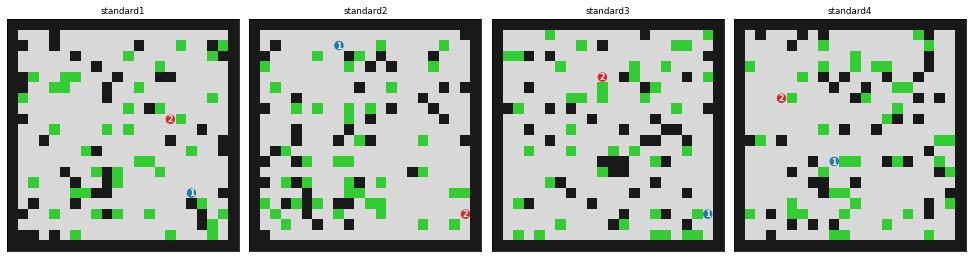

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.8))
for i in range(4):
    zeichne(plaene[f'standard{i + 1}'], axs[i], titel=f'standard{i + 1}')
plt.tight_layout()
plt.show()

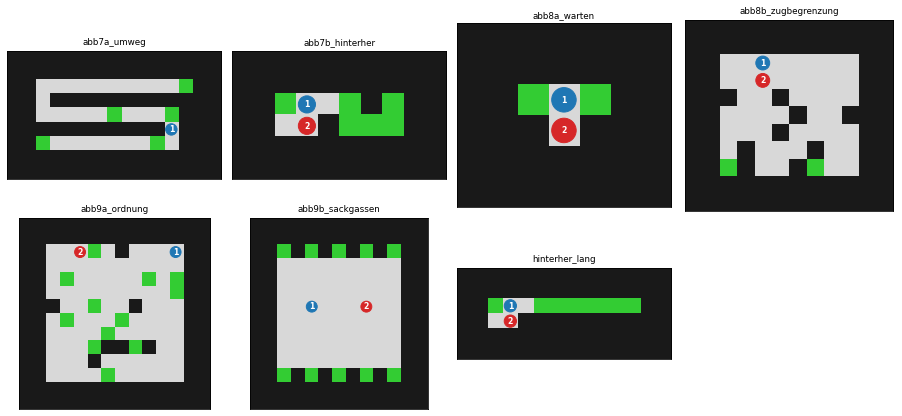

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(13, 6))
namen = ['abb7a_umweg', 'abb7b_hinterher', 'abb8a_warten', 'abb8b_zugbegrenzung', 'abb9a_ordnung', 'abb9b_sackgassen',
         'hinterher_lang']
for i in range(len(namen)):
    zeichne(plaene[namen[i]], axs[i // 4][i % 4], titel=namen[i])
axs[1][3].axis('off')
plt.tight_layout()
plt.show()

## Schritt 3: Das Spiel simulieren

Eine KI ist bei uns eine Funktion, die zu einer Spielsituation den nächsten Zug liefert: das Feld, auf das die Figur ziehen soll
(ein Nachbarfeld oder das eigene Feld zum Stehenbleiben). Damit wir verschiedene KIs gegeneinander spielen lassen können, ohne
Funktionen herumzureichen, wählt `ki_zug` die KI über ihren Namen aus. Jede KI bekommt außerdem ein eigenes `dict` namens `merker`,
in dem sie sich etwas für die nächsten Züge merken kann (z. B. ihr Ziel), und darin unter `'rest'`, wie viele Züge (beider Spieler
zusammen) in der Runde noch übrig sind.

`spiele_runde` prüft jeden Zug: Ist er ungültig, bleibt die Figur stehen. Die KI-Funktionen definieren wir in den nächsten Schritten;
`ki_zug` ruft sie erst beim Spielen auf. Die erste KI ist ganz einfach: Sie zieht zufällig.

In [ ]:
zufall = random.Random(1)


def zug_zufall(plan, ich, er):
    moeglich = [ich]
    for n in nachbarn(plan, ich):
        if n != er:
            moeglich.append(n)
    return zufall.choice(moeglich)


def ki_zug(name, plan, chips, ich, er, merker):
    """Fragt die KI mit diesem Namen nach ihrem Zug. ich, er: Felder der beiden Figuren."""
    if name == 'zufall':
        return zug_zufall(plan, ich, er)
    if name == 'nn':
        return zug_nn(plan, chips, ich, er)
    if name == 'wettlauf':
        return zug_wettlauf(plan, chips, ich, er)
    if name == 'ziele':
        return zug_ziele(plan, chips, ich, er, merker)
    if name == 'perfekt':
        return zug_perfekt(plan, chips, ich, er, merker)
    if name == 'steht':
        return ich
    print('unbekannte KI', name)


def spiele_runde(plan, ki1, ki2, zuege=400, startzahl=1):
    """Eine Runde: ki1 startet auf s1 und beginnt, ki2 startet auf s2. Jeder hat höchstens zuege Züge."""
    zufall.seed(startzahl)
    namen = [ki1, ki2]
    pos = [plan['s1'], plan['s2']]
    chips = set(plan['chips'])
    punkte = [0, 0]
    merker = [{}, {}]
    wege = [[pos[0]], [pos[1]]]
    gemacht = 0                               # Züge beider Spieler zusammen
    while gemacht < 2 * zuege and len(chips) > 0:
        k = gemacht % 2                       # wer ist dran? 0 = Spieler 1, 1 = Spieler 2
        merker[k]['rest'] = 2 * zuege - gemacht
        ziel = ki_zug(namen[k], plan, chips, pos[k], pos[1 - k], merker[k])
        if ziel == pos[k] or (ziel in nachbarn(plan, pos[k]) and ziel != pos[1 - k]):
            pos[k] = ziel
            if ziel in chips:
                chips.remove(ziel)
                punkte[k] += 1
        wege[k].append(pos[k])
        gemacht += 1
    return {'punkte': punkte, 'zuege': gemacht, 'wege': wege, 'chips': chips, 'pos': pos}


def spiel(plan, ki_a, ki_b, zuege=400):
    """Zwei Runden mit vertauschten Startfeldern. Ergebnis: Chips von ki_a und ki_b zusammen."""
    r1 = spiele_runde(plan, ki_a, ki_b, zuege)
    getauscht = dict(plan, s1=plan['s2'], s2=plan['s1'])
    r2 = spiele_runde(getauscht, ki_b, ki_a, zuege)
    return r1['punkte'][0] + r2['punkte'][1], r1['punkte'][1] + r2['punkte'][0]


r = spiele_runde(plaene['standard1'], 'zufall', 'zufall')
print('zufall gegen zufall auf standard1:', r['punkte'], 'nach', r['zuege'], 'Zügen')

zufall gegen zufall auf standard1: [13, 8] nach 800 Zügen


Zwei Zufalls-KIs sammeln in 800 Zügen zusammen nur 21 der 40 Chips ein: Sie irren ziellos herum.

## Schritt 4: Nearest Neighbour – immer zum nächsten Chip

Die erste vernünftige KI macht eine Breitensuche von ihrem Feld aus, mit dem Feld des Gegners als Hindernis (dorthin darf sie ja
nicht). Der erste Chip, den die Breitensuche findet, ist ein nächstgelegener. Damit wir den Weg dorthin kennen, merkt sich die Suche
für jedes Feld, von welchem Feld aus sie es erreicht hat (`vorher`). Von dem Chip aus gehen wir diese Kette zurück bis zum Feld direkt
neben uns: Das ist der nächste Schritt.

In [ ]:
def zug_nn(plan, chips, ich, er):
    vorher = {ich: None}
    schlange = deque([ich])
    while schlange:
        feld = schlange.popleft()
        if feld in chips:                     # nächster Chip gefunden: zurück bis zum ersten Schritt
            while vorher[feld] != ich:
                feld = vorher[feld]
            return feld
        for n in nachbarn(plan, feld):
            if n not in vorher and n != er:
                vorher[n] = feld
                schlange.append(n)
    return ich                                # kein Chip erreichbar: stehen bleiben


r = spiele_runde(plaene['standard1'], 'nn', 'steht')
print('nn allein (Gegner steht nur herum) auf standard1:', r['punkte'], 'nach', r['zuege'], 'Zügen')
r = spiele_runde(plaene['standard1'], 'nn', 'nn')
print('nn gegen nn auf standard1:', r['punkte'], 'nach', r['zuege'], 'Zügen')

nn allein (Gegner steht nur herum) auf standard1: [40, 0] nach 281 Zügen
nn gegen nn auf standard1: [19, 21] nach 165 Zügen


Allein braucht `nn` hier etwa 140 eigene Schritte für alle 40 Chips (die Zahl der Züge zählt beide Spieler).

**Abbildung 7a der Hinweise: ein Umweg.** Spieler 1 ist allein auf dem Plan. Wie viele Schritte braucht `nn`, und wie viele wären
nötig? Das Optimum finden wir mit einer Breitensuche über **Zustände** (Feld, übrige Chips): Ein Schritt führt zu einem Nachbarfeld,
und liegt dort ein Chip, ist er aus der Menge verschwunden. Der erste Zustand ohne Chips ist nach der kleinstmöglichen Zahl von
Schritten erreicht. Bei 33 freien Feldern und 5 Chips gibt es höchstens 33 · 2⁵ = 1056 Zustände, das geht sofort.

Abb. 7a: nn braucht 58 Schritte, optimal sind 42
nn:      Chip (4, 11) nach 1 Schritten
nn:      Chip (6, 10) nach 4 Schritten
nn:      Chip (4, 7) nach 11 Schritten
nn:      Chip (6, 2) nach 26 Schritten
nn:      Chip (2, 12) nach 58 Schritten
optimal: Chip (6, 10) nach 2 Schritten
optimal: Chip (6, 2) nach 10 Schritten
optimal: Chip (4, 11) nach 21 Schritten
optimal: Chip (4, 7) nach 25 Schritten
optimal: Chip (2, 12) nach 42 Schritten


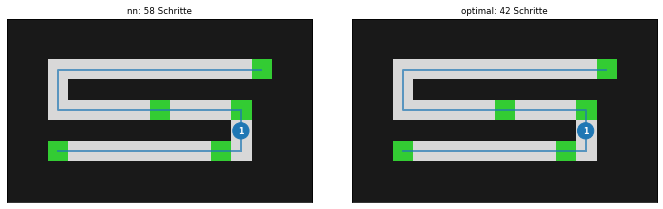

In [ ]:
def nn_tour(plan, start):
    """Schritte, die nn allein für alle Chips braucht, und ihr Weg."""
    chips = set(plan['chips'])
    feld, weg = start, [start]
    while chips:
        feld = zug_nn(plan, chips, feld, None)
        chips.discard(feld)
        weg.append(feld)
    return len(weg) - 1, weg


def kuerzeste_sammeltour(plan, start):
    """Breitensuche über (Feld, übrige Chips): kleinste Zahl von Schritten für alle Chips, und der Weg."""
    anfang = (start, frozenset(plan['chips']))
    vorher = {anfang: None}
    schlange = deque([anfang])
    while schlange:
        zustand = schlange.popleft()
        feld, chips = zustand
        if len(chips) == 0:
            weg = []
            while zustand is not None:
                weg.append(zustand[0])
                zustand = vorher[zustand]
            return len(weg) - 1, weg[::-1]
        for n in nachbarn(plan, feld):
            neu = (n, chips - {n})
            if neu not in vorher:
                vorher[neu] = zustand
                schlange.append(neu)


umweg = plaene['abb7a_umweg']
laenge_nn, weg_nn = nn_tour(umweg, umweg['s1'])
laenge_opt, weg_opt = kuerzeste_sammeltour(umweg, umweg['s1'])
print('Abb. 7a: nn braucht', laenge_nn, 'Schritte, optimal sind', laenge_opt)
for name_tour, weg in [('nn:     ', weg_nn), ('optimal:', weg_opt)]:
    reihenfolge = []
    for i in range(len(weg)):
        if weg[i] in umweg['chips'] and weg[i] not in reihenfolge:
            reihenfolge.append(weg[i])
            print(name_tour, 'Chip', weg[i], 'nach', i, 'Schritten')
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
zeichne(umweg, axs[0], wege=[weg_nn, None], titel=f'nn: {laenge_nn} Schritte')
zeichne(umweg, axs[1], wege=[weg_opt, None], titel=f'optimal: {laenge_opt} Schritte')
plt.tight_layout()
plt.show()

Das Optimum von 42 Schritten stimmt mit den Hinweisen überein: erst nach unten links, zurück, dann oben herum. `nn` nimmt zuerst den
Chip direkt über sich, läuft dann zwischen dem mittleren und dem unteren Gang hin und her und muss am Ende den ganzen Weg nach oben
rechts gehen. Nach unserer Abschrift des Bildes braucht `nn` **58** Schritte, die Hinweise nennen **56**. Wir haben die Karte
mehrfach geprüft (auch das Optimum von 42 passt); vermutlich zählen die Hinweise etwas anders oder die Heuristik dort entscheidet an
einer Stelle anders. An der Aussage ändert das nichts: Die gierige Tour kann deutlich länger als die beste sein.

## Schritt 5: Was wäre perfekt? Rückwärtsrechnung auf kleinen Karten

Auf einer kleinen Karte können wir das Spiel vollständig durchrechnen. Eine **Situation** ist `(a, b, chips)`: `a` ist das Feld
dessen, der am Zug ist, `b` das Feld des anderen, `chips` die übrigen Chips (als `frozenset`). `wert[t][situation]` ist, wie viele
Chips der Spieler am Zug **mehr** als der andere bekommt, wenn noch `t` Züge (beider Spieler zusammen) übrig sind und beide perfekt
spielen. Das ist die Formel der Lösungshinweise, nur mit der Zahl der übrigen Züge:

- `wert[0][s] = 0` (Spielende) und `wert[t][s] = 0`, wenn keine Chips mehr da sind,
- sonst `wert[t][(a, b, chips)] = max über alle Züge a → n von (c − wert[t−1][(b, n, chips ohne n)])`, wobei c = 1 ist, wenn auf n
  ein Chip liegt.

Nach meinem Zug ist der andere am Zug, deshalb sind `b` und `n` in der neuen Situation vertauscht, und sein Wert zählt für mich
negativ. Wir rechnen Schicht für Schicht: erst alle Situationen mit `t = 1`, dann `t = 2` usw.

**Ein Trick für 800 Züge:** Eine Schicht hängt nur von der vorigen ab. Ist irgendwann `wert[t]` genau gleich `wert[t − 2]`, dann ist
auch `wert[t + 1] = wert[t − 1]` usw.: Von da an wechseln sich nur noch zwei Schichten ab. Wir hören dann auf und lesen den Wert für
800 Züge in der Schicht mit derselben Parität (gerade oder ungerade) ab.

In [ ]:
def teilmengen(chips):
    """Alle Teilmengen der Chips als frozensets."""
    liste = sorted(chips)
    ergebnis = []
    for k in range(len(liste) + 1):
        for auswahl in itertools.combinations(liste, k):
            ergebnis.append(frozenset(auswahl))
    return ergebnis


def rueckwaerts(plan):
    """Berechnet die Schichten wert[0], wert[1], ... bis sie sich nur noch abwechseln. Speichert sie im Plan."""
    situationen = []
    for a in plan['frei']:
        for b in plan['frei']:
            if a != b:
                for chips in teilmengen(plan['chips']):
                    situationen.append((a, b, chips))
    schichten = [{}]
    for s in situationen:
        schichten[0][s] = 0
    while True:
        alt = schichten[-1]
        neu = {}
        for (a, b, chips) in situationen:
            if len(chips) == 0:
                neu[(a, b, chips)] = 0
                continue
            bester = None
            for n in [a] + nachbarn(plan, a):
                if n == b:
                    continue                          # auf das Feld des Gegners darf man nicht
                if n in chips:
                    w = 1 - alt[(b, n, chips - {n})]
                else:
                    w = 0 - alt[(b, n, chips)]
                if bester is None or w > bester:
                    bester = w
            neu[(a, b, chips)] = bester
        schichten.append(neu)
        if len(schichten) >= 3 and neu == schichten[-3]:
            break
    plan['schichten'] = schichten
    return len(situationen), len(schichten) - 1


def tabellenwert(plan, t, situation):
    """wert[t][situation]; ab dem Ende der Tabelle wechseln sich die letzten beiden Schichten ab."""
    schichten = plan['schichten']
    letzte = len(schichten) - 1
    if t > letzte:
        if (t - letzte) % 2 == 0:
            t = letzte
        else:
            t = letzte - 1
    return schichten[t][situation]


for name in ['abb7b_hinterher', 'abb8a_warten', 'abb8b_zugbegrenzung', 'hinterher_lang']:
    p = plaene[name]
    anzahl, t_ende = rueckwaerts(p)
    voll = frozenset(p['chips'])
    w1 = tabellenwert(p, 800, (p['s1'], p['s2'], voll))
    w2 = tabellenwert(p, 800, (p['s2'], p['s1'], voll))
    print(f'{name:20} {anzahl:6} Situationen, Schichten bis t = {t_ende:2};',
          f'Wert bei 800 Zügen: Spieler 1 beginnt {w1:+d}, Spieler 2 beginnt {w2:+d} (aus Sicht des Beginnenden)')

abb7b_hinterher        5760 Situationen, Schichten bis t = 17; Wert bei 800 Zügen: Spieler 1 beginnt +4, Spieler 2 beginnt -4 (aus Sicht des Beginnenden)
abb8a_warten             48 Situationen, Schichten bis t =  5; Wert bei 800 Zügen: Spieler 1 beginnt +1, Spieler 2 beginnt -1 (aus Sicht des Beginnenden)
abb8b_zugbegrenzung    8648 Situationen, Schichten bis t = 27; Wert bei 800 Zügen: Spieler 1 beginnt -1, Spieler 2 beginnt +1 (aus Sicht des Beginnenden)
hinterher_lang        33792 Situationen, Schichten bis t = 21; Wert bei 800 Zügen: Spieler 1 beginnt +6, Spieler 2 beginnt -6 (aus Sicht des Beginnenden)


Mit der Tabelle spielt die KI **perfekt**: Sie nimmt den Zug, der `c − wert[t−1][neue Situation]` am größten macht.

In [ ]:
def zug_perfekt(plan, chips, ich, er, merker):
    t = merker['rest']                         # übrige Züge beider Spieler, meiner eingeschlossen
    bester, bester_zug = None, ich
    for n in [ich] + nachbarn(plan, ich):
        if n == er:
            continue
        if n in chips:
            w = 1 - tabellenwert(plan, t - 1, (er, n, frozenset(chips - {n})))
        else:
            w = 0 - tabellenwert(plan, t - 1, (er, n, frozenset(chips)))
        if bester is None or w > bester:
            bester, bester_zug = w, n
    return bester_zug


for name in ['abb7b_hinterher', 'hinterher_lang']:
    p = plaene[name]
    for ki1 in ['perfekt', 'nn']:
        r = spiele_runde(p, ki1, 'perfekt')
        print(f'{name:16} Spieler 1 = {ki1:8} gegen Spieler 2 = perfekt: {r["punkte"][0]} : {r["punkte"][1]}')

abb7b_hinterher  Spieler 1 = perfekt  gegen Spieler 2 = perfekt: 5 : 1
abb7b_hinterher  Spieler 1 = nn       gegen Spieler 2 = perfekt: 1 : 5
hinterher_lang   Spieler 1 = perfekt  gegen Spieler 2 = perfekt: 7 : 1
hinterher_lang   Spieler 1 = nn       gegen Spieler 2 = perfekt: 1 : 7


**Abbildung 7b** (Spieler 1 beginnt): Spielt Spieler 1 perfekt, läuft er nach rechts und holt 5 Chips, die rote KI (Spieler 2)
bekommt nur den einen Chip links; der Wert für Spieler 1 ist +4. Genau das sagen die Hinweise: Rot kann einem guten Gegner nicht mehr
als einen Chip abringen. `nn` dagegen nimmt zuerst den Chip direkt links (Abstand 1), Rot schlüpft nach oben und läuft vor ihm her:
1 : 5, wie in den Hinweisen („alle bis auf einen Chip“). In der verlängerten Karte `hinterher_lang` mit n = 8 Chips bekommt `nn` 1
statt 7 Chips, also n − 2 = 6 weniger als ein perfekter Spieler, wie es die Hinweise allgemein beschreiben.

**Abbildung 8: Die Zugbegrenzung zählt.** In `abb8a_warten` steht Spieler 1 zwischen zwei Chips und versperrt Spieler 2 den Weg.
Nimmt er früh einen Chip, schlüpft Spieler 2 hinaus und holt den anderen (1 : 1). Wartet er bis zu seinem letzten Zug, reicht die
Zeit für Spieler 2 nicht mehr: Der Wert ist +1 für Spieler 1, egal wer beginnt (−1 aus Sicht von Spieler 2, wenn er beginnt). Die
Tabelle zeigt, wie das von der Zahl der übrigen Züge abhängt:

In [ ]:
for name in ['abb8a_warten', 'abb8b_zugbegrenzung']:
    p = plaene[name]
    voll = frozenset(p['chips'])
    werte = []
    for t in range(1, 31):
        werte.append(tabellenwert(p, t, (p['s2'], p['s1'], voll)))
    print(f'{name}: Spieler 2 beginnt, Wert für ihn bei t = 1 bis 30 übrigen Zügen:')
    print('  ', werte)

abb8a_warten: Spieler 2 beginnt, Wert für ihn bei t = 1 bis 30 übrigen Zügen:
   [0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
abb8b_zugbegrenzung: Spieler 2 beginnt, Wert für ihn bei t = 1 bis 30 übrigen Zügen:
   [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


Bei **Abbildung 8b** beginnt die rote KI (Spieler 2). Bei wenigen übrigen Zügen (bis 12) ist der Wert 0, dann +1: Rot gewinnt mit einem
Chip Vorsprung, auch bei 800 Zügen. Beginnt Spieler 1, ist der Wert für ihn −1 (siehe oben), Rot gewinnt also in beiden Fällen.
Die Hinweise erklären, dass Rot diesen Sieg nur wegen der Begrenzung auf 400 Züge erzwingen kann (ohne Grenze könnte der andere
immer weiter ausweichen). Das prüfen wir hier nicht nach; unsere Rechnung kennt nur Spiele mit Zugbegrenzung.

**Warum das nicht für 20 × 20 geht:** Die Karte 8b hat 47 freie Felder und 2 Chips und schon 8 648 Situationen pro Schicht. Mit
360 freien Feldern und 40 Chips wären es 360 · 359 · 2⁴⁰ ≈ 1,4 · 10¹⁷, dazu noch die Zahl der übrigen Züge. Auf großen Plänen
brauchen wir also Heuristiken. Die Rückwärtsrechnung zeigt uns aber auf kleinen Karten, was „gut“ ist.

## Schritt 6: Wettlauf – den Gegner beachten

`nn` läuft auch zu Chips, die der Gegner sicher zuerst bekommt. Die KI `wettlauf` vergleicht deshalb mit der Abstandstabelle für jeden
Chip ihren Abstand mit dem des Gegners. Weil sie gerade am Zug ist, kommt sie bei **gleichem** Abstand zuerst an. Unter den Chips, die
sie so vor dem Gegner erreicht, nimmt sie den nächsten. Gibt es keinen, verhält sie sich wie `nn`.

Für den Schritt in Richtung Ziel brauchen wir kein `vorher` mehr: Ein Nachbarfeld liegt auf einem kürzesten Weg zum Ziel, wenn sein
Abstand zum Ziel um 1 kleiner ist als unserer. Steht dort gerade der Gegner, nehmen wir einen anderen solchen Nachbarn; gibt es
keinen, hilft wieder `zug_nn` (das um den Gegner herumläuft).

In [ ]:
def schritt_richtung(plan, ich, er, ziel):
    """Ein Nachbarfeld auf einem kürzesten Weg von ich zu ziel (nicht das Feld des Gegners), sonst None."""
    abstand_ziel = plan['abstand'][ziel]
    for n in nachbarn(plan, ich):
        if n != er and abstand_ziel[n] == abstand_ziel[ich] - 1:
            return n
    return None


def zug_wettlauf(plan, chips, ich, er):
    mein = plan['abstand'][ich]
    sein = plan['abstand'][er]
    bestes = None
    for c in sorted(chips):
        if mein[c] <= sein[c]:                         # ich bin am Zug: bei Gleichstand bin ich zuerst da
            if bestes is None or mein[c] < mein[bestes]:
                bestes = c
    if bestes is None:
        return zug_nn(plan, chips, ich, er)
    schritt = schritt_richtung(plan, ich, er, bestes)
    if schritt is None:
        return zug_nn(plan, chips, ich, er)
    return schritt


for name in ['standard1', 'standard2', 'standard3', 'standard4']:
    print(f'{name}: nn : wettlauf = {spiel(plaene[name], "nn", "wettlauf")}')

standard1: nn : wettlauf = (38, 42)
standard2: nn : wettlauf = (36, 44)
standard3: nn : wettlauf = (40, 40)
standard4: nn : wettlauf = (32, 48)


Jedes Spiel besteht aus zwei Runden, es geht also um 80 Chips. `wettlauf` gewinnt auf drei Plänen und spielt einmal unentschieden.
(Ob das allgemein so ist, prüfen wir im Turnier in Schritt 8.)

## Schritt 7: Ziele – der Chip-basierte Ansatz der Hinweise

**Kandidaten.** Die Hinweise beobachten: Wenn die Spieler weit voneinander entfernt sind, ist es meist das Beste, einen Chip
auszuwählen und ihn auf kürzestem Weg zu holen. Liegt auf einem kürzesten Weg zu Chip b ein anderer Chip a, gibt es keinen Grund, b
zuerst anzusteuern: Man käme ohne Umweg an a vorbei. Die Hinweise schreiben dafür a ≺ b. Mit der Abstandstabelle ist das leicht zu
prüfen: **a liegt auf einem kürzesten Weg von K nach b, wenn abstand(K, a) + abstand(a, b) = abstand(K, b)**. Die Kandidaten sind
die Chips b, vor denen kein anderer Chip liegt; die Hinweise nennen diese Menge G_K.

**Abbildung 9a** zeichnet für jeden Spieler und jeden Chip die Kandidaten als rote Linien ein. Wir vergleichen mit unserer Rechnung:

Spieler 1 (Kopf, oben rechts): [(2, 5), (4, 11)]
Spieler 2 (rot, oben links):   [(2, 5), (4, 3), (11, 6)]
Kandidaten von den Chips aus, wie viele: [3, 4, 6, 2, 4, 8, 6, 6, 5, 4, 5, 3]


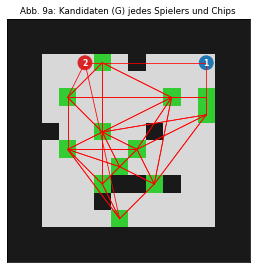

In [ ]:
def kandidaten(plan, von, chips):
    """Die Menge G der Hinweise: Chips b, auf deren kürzesten Wegen von 'von' aus kein anderer Chip liegt."""
    abstand_von = plan['abstand'][von]
    ergebnis = []
    for b in sorted(chips):
        frei_davor = True
        for a in chips:
            if a != b and abstand_von[a] + plan['abstand'][a][b] == abstand_von[b]:
                frei_davor = False
                break
        if frei_davor:
            ergebnis.append(b)
    return ergebnis


p9 = plaene['abb9a_ordnung']
print('Spieler 1 (Kopf, oben rechts):', kandidaten(p9, p9['s1'], p9['chips']))
print('Spieler 2 (rot, oben links):  ', kandidaten(p9, p9['s2'], p9['chips']))
g9 = {}
for c in sorted(p9['chips']):
    g9[c] = kandidaten(p9, c, p9['chips'] - {c})
print('Kandidaten von den Chips aus, wie viele:', [len(g9[c]) for c in sorted(p9['chips'])])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
zeichne(p9, ax, titel='Abb. 9a: Kandidaten (G) jedes Spielers und Chips')
for von in [p9['s1'], p9['s2']] + sorted(p9['chips']):
    for b in kandidaten(p9, von, p9['chips'] - {von}):
        ax.plot([von[1], b[1]], [von[0], b[0]], color='red', linewidth=0.8)
plt.show()

Spieler 1 hat genau zwei Kandidaten, den Chip zwei Felder unter sich und den Chip oben links neben Rot; Spieler 2 hat drei: den Chip
direkt rechts, den Chip schräg unten links und den Chip ganz unten, zu dem ein kürzester Weg links an den Hindernissen vorbei führt
(im Bild der Hinweise als gebogene Linie). Das passt zu Abbildung 9a. Die Linien zwischen Chips zeichnen wir als gerade Strecken.

**Bewertung durch ein Wettrennen.** Welchen Kandidaten soll man nehmen? Wir spielen das Spiel in Gedanken grob zu Ende: Ich laufe zu
meinem Kandidaten, danach laufen beide immer zum nächsten übrigen Chip. Das rechnen wir nicht Zug für Zug, sondern mit
**Ankunftszeiten** aus der Abstandstabelle: Wer seinen nächsten Chip früher erreicht, bekommt ihn, steht danach dort und hat die Zeit
verbraucht. Der andere sucht sich dann von seinem alten Feld aus einen neuen Chip (eine Vereinfachung: in Wirklichkeit wäre er schon
ein Stück gelaufen). Bei gleicher Zeit gewinnt der, der am Zug ist (er bekommt einen halben Schritt Vorsprung). Ergebnis: meine Chips
minus seine. Den Kandidaten mit dem besten Ergebnis steuern wir an und **behalten ihn als Ziel**, bis er weg ist. Würde die KI in jedem
Zug neu wählen, könnte sie zwischen zwei Zielen hin- und herpendeln; bei zwei solchen KIs kam es in unseren Versuchen zu Runden, in
denen fast niemand mehr Chips sammelte.

Ein Zähler zählt die Schritte der Wettrennen (wie oft ein nächster Chip gesucht wird), damit wir den Rechenaufwand sehen.

In [ ]:
ZAEHLER = {'rennschritte': 0}


def naechster_chip(plan, feld, chips):
    abstand = plan['abstand'][feld]
    bester = None
    for c in sorted(chips):
        if bester is None or abstand[c] < abstand[bester]:
            bester = c
    return bester


def wettrennen(plan, chips, ich, er, erstes_ziel):
    """Schätzung: ich hole zuerst erstes_ziel, dann laufen beide immer zum nächsten Chip. Ergebnis: meine minus seine Chips."""
    rest = set(chips)
    zeit_ich, zeit_er = 0, 0.5            # ich bin am Zug: bei gleicher Schrittzahl bin ich zuerst da
    differenz = 0
    mein_ziel = erstes_ziel
    while len(rest) > 0:
        ZAEHLER['rennschritte'] += 1
        if mein_ziel not in rest:
            mein_ziel = naechster_chip(plan, ich, rest)
        sein_ziel = naechster_chip(plan, er, rest)
        ankunft_ich = zeit_ich + plan['abstand'][ich][mein_ziel]
        ankunft_er = zeit_er + plan['abstand'][er][sein_ziel]
        if ankunft_ich < ankunft_er:          # ich bin zuerst da
            zeit_ich, ich = ankunft_ich, mein_ziel
            rest.remove(mein_ziel)
            differenz += 1
        else:
            zeit_er, er = ankunft_er, sein_ziel
            rest.remove(sein_ziel)
            differenz -= 1
    return differenz


def zug_ziele(plan, chips, ich, er, merker):
    if merker.get('ziel') not in chips:         # noch kein Ziel oder Ziel ist weg: neu wählen
        bestes, bester_wert = None, None
        for c in kandidaten(plan, ich, chips):
            w = wettrennen(plan, chips, ich, er, c)
            if bester_wert is None or w > bester_wert or (w == bester_wert and plan['abstand'][ich][c] < plan['abstand'][ich][bestes]):
                bestes, bester_wert = c, w
        merker['ziel'] = bestes
    schritt = schritt_richtung(plan, ich, er, merker['ziel'])
    if schritt is None:
        return zug_nn(plan, chips, ich, er)
    return schritt


for name in ['standard1', 'standard2', 'standard3', 'standard4']:
    print(f'{name}: nn : ziele = {spiel(plaene[name], "nn", "ziele")}   wettlauf : ziele = {spiel(plaene[name], "wettlauf", "ziele")}')

standard1: nn : ziele = (31, 49)   wettlauf : ziele = (36, 44)
standard2: nn : ziele = (30, 50)   wettlauf : ziele = (34, 46)
standard3: nn : ziele = (34, 46)   wettlauf : ziele = (37, 43)
standard4: nn : ziele = (36, 44)   wettlauf : ziele = (38, 42)


`ziele` gewinnt jedes dieser acht Spiele. Wie viel rechnet die KI dafür? Wir zählen in einer Runde gegen `nn`, wie viele
Wettrennen-Schritte jeder ihrer Züge kostet:

In [ ]:
p = plaene['standard1']
pos = [p['s1'], p['s2']]
chips = set(p['chips'])
merker = {}
schritte_pro_zug = []
k = 0
while len(chips) > 0:
    if k == 0:
        vorher_schritte = ZAEHLER['rennschritte']
        ziel = zug_ziele(p, chips, pos[0], pos[1], merker)
        schritte_pro_zug.append(ZAEHLER['rennschritte'] - vorher_schritte)
    else:
        ziel = zug_nn(p, chips, pos[1], pos[0])
    pos[k] = ziel
    chips.discard(ziel)
    k = 1 - k
mit_wahl = [s for s in schritte_pro_zug if s > 0]
print('Züge von ziele:', len(schritte_pro_zug), ' davon mit neuer Zielwahl:', len(mit_wahl))
print('Wettrennen-Schritte: zusammen', sum(schritte_pro_zug), ' höchstens', max(schritte_pro_zug), 'in einem Zug')

Züge von ziele: 87  davon mit neuer Zielwahl: 23
Wettrennen-Schritte: zusammen 2858  höchstens 320 in einem Zug


Nur bei gut einem Viertel der Züge wird neu gewählt; dann kostet ein Zug höchstens einige hundert Rennschritte. Jeder Rennschritt sucht
zweimal den nächsten Chip unter höchstens 40, das sind in einem Zug höchstens 320 · 2 · 40 = 25 600 einfache Vergleiche, meist
viel weniger. Für einen Computer ist das wenig (Bruchteile einer Sekunde). Die Rechenzeit ist also
unkritisch, und die KI bleibt nie aus Zeitmangel stehen. Teuer ist nur die Abstandstabelle am Anfang (etwa 130 000 Schritte der
Breitensuche, einmal pro Plan).

**Augenblicksbilder.** So sieht eine Runde auf `standard1` aus: `ziele` ist Spieler 1 (blau), `nn` Spieler 2 (rot). Wir lassen die Runde
nach 15, 30 und 45 Zügen jedes Spielers anhalten (eine Runde mit weniger Zügen ist genau der Anfang der ganzen Runde) und zeichnen die
bisherigen Wege und die übrigen Chips.

ganze Runde: ziele 22  nn 18  nach 173 Zügen


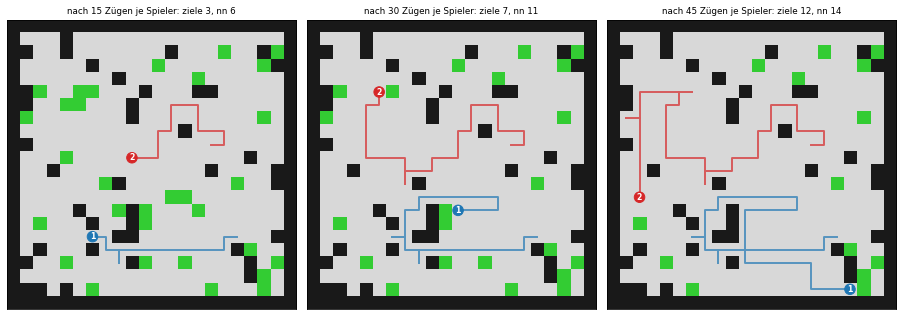

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
for i in range(3):
    zuege_bis_hier = 15 * (i + 1)
    r = spiele_runde(plaene['standard1'], 'ziele', 'nn', zuege=zuege_bis_hier)
    zeichne(plaene['standard1'], axs[i], chips=r['chips'], positionen=r['pos'], wege=r['wege'],
            titel=f'nach {zuege_bis_hier} Zügen je Spieler: ziele {r["punkte"][0]}, nn {r["punkte"][1]}')
plt.tight_layout()
plt.show()
r = spiele_runde(plaene['standard1'], 'ziele', 'nn')
print('ganze Runde: ziele', r['punkte'][0], ' nn', r['punkte'][1], ' nach', r['zuege'], 'Zügen')

Die beiden Spieler teilen den Plan schnell unter sich auf: `ziele` sammelt im unteren Teil, `nn` läuft nach oben und dann nach links.
Am Anfang liegt `nn` vorn (6 : 3, 11 : 7, 14 : 12), weil dort die Chips dichter liegen. Am Ende gewinnt aber `ziele` die Runde mit
22 : 18 (nach 173 Zügen beider Spieler). Ein Zwischenstand sagt bei Tourality wenig: Entscheidend ist, wer die Chips bekommt, die
zwischen den beiden liegen.

## Schritt 8: Das Turnier

Jede KI spielt gegen jede andere auf den vier Standard-Plänen, jedes Spiel mit zwei Runden. Wir zählen die gewonnenen, unentschiedenen
und verlorenen Spiele und die Chips.

In [ ]:
KIS = ['zufall', 'nn', 'wettlauf', 'ziele']


def turnier(plan_liste):
    bilanz = {}
    for ki in KIS:
        bilanz[ki] = [0, 0, 0, 0]                 # gewonnen, unentschieden, verloren, Chips
    for i in range(len(KIS)):
        for j in range(i + 1, len(KIS)):
            a, b = KIS[i], KIS[j]
            summe_a, summe_b, siege_a, siege_b = 0, 0, 0, 0
            for plan in plan_liste:
                ca, cb = spiel(plan, a, b)
                summe_a += ca
                summe_b += cb
                bilanz[a][3] += ca
                bilanz[b][3] += cb
                if ca > cb:
                    bilanz[a][0] += 1
                    bilanz[b][2] += 1
                    siege_a += 1
                elif ca < cb:
                    bilanz[b][0] += 1
                    bilanz[a][2] += 1
                    siege_b += 1
                else:
                    bilanz[a][1] += 1
                    bilanz[b][1] += 1
            print(f'{a:8} gegen {b:8}  Chips {summe_a:4} : {summe_b:<4}  Siege {siege_a} : {siege_b}')
    print()
    print('KI        gew.  unent. verl.  Chips')
    for ki in KIS:
        g, u, v, c = bilanz[ki]
        print(f'{ki:8} {g:5} {u:6} {v:6} {c:6}')
    return bilanz


bilanz_standard = turnier([plaene['standard1'], plaene['standard2'], plaene['standard3'], plaene['standard4']])

zufall   gegen nn        Chips   30 : 290   Siege 0 : 4
zufall   gegen wettlauf  Chips   34 : 286   Siege 0 : 4
zufall   gegen ziele     Chips   30 : 290   Siege 0 : 4
nn       gegen wettlauf  Chips  146 : 174   Siege 0 : 3
nn       gegen ziele     Chips  131 : 189   Siege 0 : 4
wettlauf gegen ziele     Chips  145 : 175   Siege 0 : 4

KI        gew.  unent. verl.  Chips
zufall       0      0     12     94
nn           4      1      7    567
wettlauf     7      1      4    605
ziele       12      0      0    654


Vier Pläne sind wenig. Deshalb noch ein Turnier auf 20 weiteren Zufallsplänen (Startzahlen 101 bis 120):

In [ ]:
weitere = []
for startzahl in range(101, 121):
    weitere.append(zufallsplan(startzahl))
bilanz_weitere = turnier(weitere)

zufall   gegen nn        Chips   81 : 1519  Siege 0 : 20
zufall   gegen wettlauf  Chips   90 : 1510  Siege 0 : 20
zufall   gegen ziele     Chips  129 : 1471  Siege 0 : 20
nn       gegen wettlauf  Chips  806 : 794   Siege 10 : 8
nn       gegen ziele     Chips  671 : 929   Siege 0 : 20
wettlauf gegen ziele     Chips  686 : 914   Siege 1 : 19

KI        gew.  unent. verl.  Chips
zufall       0      0     60    300
nn          30      2     28   2996
wettlauf    29      2     29   2990
ziele       59      0      1   3314


`ziele` gewinnt 59 von 60 Spielen: alle gegen `nn` und `zufall`, gegen `wettlauf` 19 von 20. Überraschend: `wettlauf` ist auf diesen
20 Plänen **nicht** besser als `nn` (8 Siege, 10 Niederlagen, 2 Unentschieden, fast gleich viele Chips). Die vier Standard-Pläne hatten
einen zu günstigen Eindruck gemacht. Nur den nächsten Chip zu nehmen, den man vor dem Gegner erreicht, ist eben auch kurzsichtig: Man
lässt Chips liegen, die man danach nicht mehr bekommt, und läuft oft weit weg. Damit erfüllt sie das Bewertungskriterium der Hinweise, einer einfachen Nearest-Neighbour-KI überlegen zu sein, und sie
bezieht den Gegner ein (über das Wettrennen). Wie sie sich gegen die KIs der damaligen Teilnehmer geschlagen hätte, wissen wir nicht.

**Die kleinen Karten.** Und wie spielen unsere KIs gegen den perfekten Spieler aus Schritt 5? Jede KI spielt als Spieler 1 gegen
`perfekt` als Spieler 2, zum Vergleich auch `perfekt` gegen `perfekt`:

In [ ]:
for name in ['abb7b_hinterher', 'hinterher_lang', 'abb8a_warten', 'abb8b_zugbegrenzung']:
    zeile = f'{name:20}'
    for ki in ['nn', 'wettlauf', 'ziele', 'perfekt']:
        r = spiele_runde(plaene[name], ki, 'perfekt')
        zeile += f'  {ki} {r["punkte"][0]}:{r["punkte"][1]}'
    print(zeile)

abb7b_hinterher       nn 1:5  wettlauf 1:5  ziele 5:1  perfekt 5:1
hinterher_lang        nn 1:7  wettlauf 1:7  ziele 7:1  perfekt 7:1
abb8a_warten          nn 1:1  wettlauf 1:1  ziele 1:1  perfekt 1:0
abb8b_zugbegrenzung   nn 0:1  wettlauf 0:1  ziele 0:1  perfekt 0:1


In Abbildung 7b und der verlängerten Karte erkennt nur `ziele`, dass die Chips rechts ihr gehören, wenn sie sofort losgeht: Das
Wettrennen zeigt, dass der Chip links zwar näher ist, danach aber Rot vorneweg läuft. Sie spielt dort so gut wie der perfekte Spieler.
`wettlauf` nimmt wie `nn` den Chip links, denn den erreicht sie ja vor Rot, und verliert 1 : 5 bzw. 1 : 7. Die Feinheit der
Zugbegrenzung in Abbildung 8a (bis zum letzten Zug warten) kennen unsere Heuristiken nicht: Sie holen 1 : 1 statt 1 : 0. In
Abbildung 8b verliert auch der perfekte Spieler 1 mit 0 : 1, dort sind unsere KIs nicht schlechter.

## Für Neugierige

### Wie groß ist die Kandidatenmenge G?

Die Hinweise schreiben (Fußnote 15): Bei fast allen zufälligen Spielplänen lag |G_K| für alle Positionen von K unter 15, für die
meisten Positionen bestand G_K aus 5 bis 10 Elementen. Wir zählen für jedes freie Feld unserer vier Standard-Pläne (vor dem ersten
Zug, alle 40 Chips liegen noch), wie viele Kandidaten man von dort aus hat. Steht man auf einem Chip, zählt dieser nicht mit.

In [ ]:
for name in ['standard1', 'standard2', 'standard3', 'standard4', 'abb9b_sackgassen']:
    p = plaene[name]
    groessen = []
    for feld in sorted(p['frei']):
        groessen.append(len(kandidaten(p, feld, p['chips'] - {feld})))
    fuenf_bis_zehn = 0
    for g in groessen:
        if 5 <= g <= 10:
            fuenf_bis_zehn += 1
    print(f'{name:17} {len(groessen)} Felder, |G| höchstens {max(groessen):2}, Mittelwert {sum(groessen) / len(groessen):4.1f},',
          f'zwischen 5 und 10: {100 * fuenf_bis_zehn / len(groessen):3.0f} Prozent')

standard1         360 Felder, |G| höchstens 10, Mittelwert  5.6, zwischen 5 und 10:  69 Prozent
standard2         360 Felder, |G| höchstens 13, Mittelwert  5.8, zwischen 5 und 10:  68 Prozent
standard3         360 Felder, |G| höchstens 12, Mittelwert  6.1, zwischen 5 und 10:  73 Prozent
standard4         360 Felder, |G| höchstens 14, Mittelwert  6.4, zwischen 5 und 10:  60 Prozent
abb9b_sackgassen  82 Felder, |G| höchstens 10, Mittelwert  9.9, zwischen 5 und 10: 100 Prozent


Das passt zu den Hinweisen: |G| ist immer unter 15 (höchstens 14), im Mittel etwa 6, und 60 bis 73 Prozent der Felder haben 5 bis 10
Kandidaten (die übrigen meist weniger). Statt 40 Chips muss `ziele` also nur eine Handvoll bewerten. **Abbildung 9b** zeigt den schlechtesten
Fall: Alle Chips liegen in Nischen, kein Chip liegt auf dem Weg zu einem anderen, also ist jeder Chip ein Kandidat (10 von einem Feld
in der Mitte aus, 9 aus einer Nische, weil der eigene Chip dann fehlt).

### Ohne Zugbegrenzung rechnen – eine Falle

Die Hinweise schlagen vor, die Zahl der übrigen Züge wegzulassen, damit es weniger Situationen gibt. Dann kann sich eine Situation
wiederholen; die Rekursion bekommt sich selbst als Unteraufruf. Für diesen Fall nehmen die Hinweise den Wert 0 an und merken sich die
berechneten Werte (Memoisierung). Wir probieren das auf den kleinen Karten aus:

In [ ]:
def wert_ohne_grenze(plan, ich, er, chips, gemerkt, in_arbeit):
    """Rechenvorschrift der Hinweise: Werte merken, eine Situation, die gerade berechnet wird, zählt 0."""
    situation = (ich, er, chips)
    if len(chips) == 0:
        return 0
    if situation in gemerkt:
        return gemerkt[situation]
    if situation in in_arbeit:
        return 0
    in_arbeit.add(situation)
    bester = None
    for n in [ich] + nachbarn(plan, ich):
        if n == er:
            continue
        if n in chips:
            w = 1 - wert_ohne_grenze(plan, er, n, chips - {n}, gemerkt, in_arbeit)
        else:
            w = 0 - wert_ohne_grenze(plan, er, n, chips, gemerkt, in_arbeit)
        if bester is None or w > bester:
            bester = w
    in_arbeit.remove(situation)
    gemerkt[situation] = bester
    return bester


for name in ['abb7b_hinterher', 'abb8a_warten']:
    p = plaene[name]
    voll = frozenset(p['chips'])
    w = wert_ohne_grenze(p, p['s1'], p['s2'], voll, {}, set())
    print(f'{name}: ohne Grenze {w:+d}, mit 400 Zügen (Schritt 5) {tabellenwert(p, 800, (p["s1"], p["s2"], voll)):+d}')

abb7b_hinterher: ohne Grenze +1, mit 400 Zügen (Schritt 5) +4
abb8a_warten: ohne Grenze +0, mit 400 Zügen (Schritt 5) +1


Bei Abbildung 8a passt das: Ohne Grenze bringt das Warten nichts mehr, der Wert ist 0 statt +1. Bei Abbildung 7b kommt aber +1 heraus,
obwohl Spieler 1 sicher 5 : 1 erreichen kann (er geht einfach sofort nach rechts, dafür braucht er keine Zugbegrenzung). Der Grund:
Ein gemerkter Wert wurde unter der Annahme „die laufende Situation zählt 0“ berechnet und gilt deshalb nur auf diesem einen Weg durch
den Spielbaum. Später wird er auch auf anderen Wegen benutzt, wo er falsch ist. Die Hinweise schreiben, dass das Ergebnis des ersten
Aufrufs trotzdem stimmt; in unserem Nachbau ist das nicht so. (Das Problem ist in der Spieleprogrammierung bekannt; die Rückwärtsrechnung
aus Schritt 5 mit der Zahl der übrigen Züge hat es nicht.) Für die eigentliche KI spielt es keine Rolle, weil wir auf großen Plänen
ohnehin nicht so rechnen.

### Weitere Ideen

- **Minimax mit begrenzter Tiefe in der Nähe des Gegners:** Die Hinweise empfehlen, in Konfliktsituationen einige Züge vorauszurechnen
  und die Blätter mit einer Bewertungsfunktion zu schätzen (mit Alpha-Beta-Pruning). Wir haben das mit 4 Halbzügen und dem Wettrennen
  als Bewertung ausprobiert: Es war nicht besser als `ziele` (auf 8 Zufallsplänen 284 : 316 Chips), und in manchen Runden wurden bis zum Ende der 400 Züge nicht
  mehr alle Chips eingesammelt, weil die KI in der Nähe des Gegners hin- und herzog. Eine
  gute Bewertungsfunktion für das Nahduell ist der schwierige Teil.
- **Die Zugbegrenzung nutzen** wie in Abbildung 8: im Endspiel den Gegner einsperren oder bis zum letzten Zug warten. Wenn nur noch
  wenige Chips übrig sind und die Spieler nahe beieinander stehen, könnte man die Rückwärtsrechnung aus Schritt 5 auf einen kleinen
  Ausschnitt anwenden.
- **Monte-Carlo-Verfahren:** viele zufällige Spielverläufe durchspielen und den Zug wählen, der im Mittel am besten abschneidet.
- **Erweiterungen der Hinweise:** größere Pläne, allgemeine Graphen statt Gitter, mehr als zwei Spieler oder Teams.

## Zum Schluss: Die kürzeste Sammeltour mit MiniZinc

Ein ganzes Spiel zu zweit kann MiniZinc nicht durchrechnen: Ein Modell beschreibt Bedingungen an eine Lösung, nicht einen Gegner, der
auf meine Züge reagiert. Eine Teilfrage passt aber gut, und die Hinweise nennen sie ausdrücklich als schweres Problem: **Wie schnell kann
ein Spieler allein alle Chips einsammeln?** In Abbildung 7a hat unsere Breitensuche über (Feld, übrige Chips) das beantwortet, bei
40 Chips gäbe es aber 2⁴⁰ Chipmengen. Für MiniZinc ist es ein **Problem des Handlungsreisenden**:

- Knoten 0 ist das Startfeld, Knoten 1 bis n sind die Chips. `d[i, j]` ist der Abstand aus der Abstandstabelle.
- `nach[i]` ist der Knoten, der nach i besucht wird. `circuit(nach)` verlangt, dass die Nachfolger einen einzigen Kreis durch alle
  Knoten bilden (ein globaler Constraint, ähnlich wie `alldifferent`).
- Der Kreis kehrt am Ende zum Start zurück. Diesen Rückweg soll man nicht zählen, deshalb ist `d[i, 0] = 0`. So ist die Länge des
  Kreises genau die Länge des Weges vom Start durch alle Chips.

In [ ]:
def als_dzn(plan, start):
    """Datendatei für das Tour-Modell: Startfeld und Chips in fester Reihenfolge."""
    orte = [start] + sorted(plan['chips'])
    n = len(orte) - 1
    zeilen = []
    for a in orte:
        werte = []
        for j in range(len(orte)):
            if j == 0:
                werte.append('0')                     # Rückweg zum Start zählt nicht
            else:
                werte.append(str(plan['abstand'][a][orte[j]]))
        zeilen.append(', '.join(werte))
    return f'n = {n};\nd = array2d(0..{n}, 0..{n}, [\n' + ',\n'.join(zeilen) + '\n]);'


def tour_aus_nach(plan, start, nach):
    """Liest die Reihenfolge der Chips aus dem Nachfolger-Array und rechnet die Länge nach."""
    orte = [start] + sorted(plan['chips'])
    laenge, i = 0, 0
    while nach[i] != 0:
        laenge += plan['abstand'][orte[i]][orte[nach[i]]]
        i = nach[i]
    return laenge


print(als_dzn(plaene['abb7a_umweg'], plaene['abb7a_umweg']['s1']))

n = 5;
d = array2d(0..5, 0..5, [
0, 22, 5, 1, 10, 2,
0, 0, 17, 21, 32, 24,
0, 17, 0, 4, 15, 7,
0, 21, 4, 0, 11, 3,
0, 32, 15, 11, 0, 8,
0, 24, 7, 3, 8, 0
]);


Modell und Ergebnis für Abbildung 7a (Solver Chuffed):

```minizinc
include "globals.mzn";

int: n;                                  % Anzahl der Chips
array[0..n, 0..n] of int: d;             % Abstände; 0 = Startfeld, d[i, 0] = 0
array[0..n] of var 0..n: nach;           % nach[i]: der Knoten nach i

constraint circuit(nach);                % ein Kreis durch alle Knoten

var int: laenge = sum(i in 0..n)(d[i, nach[i]]);

solve minimize laenge;

output ["laenge = \(laenge)\n", "nach = \(nach)\n"];
```

**Ausgabe:**

```
laenge = 42
nach = [5, 0, 1, 2, 3, 4]
----------
==========
```

Wie in Schritt 4: 42 Schritte. Die Python-Zelle prüft die Reihenfolge nach (die Ausgabe oben kopiert):

In [ ]:
nach_7a = [5, 0, 1, 2, 3, 4]
print('Länge der Tour:', tour_aus_nach(plaene['abb7a_umweg'], plaene['abb7a_umweg']['s1'], nach_7a))

Länge der Tour: 42


Mit derselben Datendatei-Funktion rechnen wir die Karten aus Abbildung 9 (Spieler 1 allein, von s1 aus). Chuffed braucht jeweils unter
einer Sekunde:

- `abb9a_ordnung` (12 Chips): **laenge = 36**
- `abb9b_sackgassen` (10 Chips): **laenge = 47**

Zum Vergleich die Tour von `nn` und die Breitensuche über (Feld, übrige Chips) aus Schritt 4 (bei 12 Chips gibt es schon
93 · 2¹² ≈ 380 000 Zustände, das dauert ein paar Sekunden):

In [ ]:
for name in ['abb9a_ordnung', 'abb9b_sackgassen']:
    p = plaene[name]
    print(f'{name:17} nn: {nn_tour(p, p["s1"])[0]} Schritte, kürzeste Sammeltour: {kuerzeste_sammeltour(p, p["s1"])[0]} Schritte')
nn_standard = []
for i in range(1, 5):
    p = plaene[f'standard{i}']
    nn_standard.append(nn_tour(p, p['s1'])[0])
print('nn allein auf standard1 bis standard4 (von s1 aus):', nn_standard, 'Schritte')

abb9a_ordnung     nn: 42 Schritte, kürzeste Sammeltour: 36 Schritte
abb9b_sackgassen  nn: 50 Schritte, kürzeste Sammeltour: 47 Schritte
nn allein auf standard1 bis standard4 (von s1 aus): [141, 148, 146, 148] Schritte


MiniZinc und die Breitensuche stimmen überein. `nn` braucht bei Abbildung 9a 6 Schritte mehr als nötig (42 statt 36), bei 9b 3 Schritte
mehr (50 statt 47).

**Die Grenze: 40 Chips.** Für die Standard-Pläne haben wir das Modell außerhalb des Notebooks laufen lassen (die Zeiten sind die
unseres Rechners). Mit einer Minute Zeit pro Plan fand keiner der Solver eine Tour, die kürzer als die von `nn` war (141 bis 148
Schritte, siehe oben): Chuffed lieferte Touren mit 204 bis 291 Schritten, HiGHS 149 bis 224, und CP-SAT wurde nicht fertig und musste
von Hand beendet werden. HiGHS ist ein **MIP-Solver**: Er rechnet mit linearen Ungleichungen, MiniZinc übersetzt `circuit` dafür
selbst. Auf kleineren Zufallsplänen (`zufallsplan(1, anzahl_chips=k)`) sieht man, wo es schwierig wird:

| Chips | 10 | 15 | 20 | 25 | 30 |
|---|---|---|---|---|---|
| Chuffed | 0,5 s | 0,7 s | 10 s | nach 1 min nicht fertig | nach 1 min nicht fertig |
| HiGHS | 1 s | 4 s | 9 s | 31 s | 41 s |

Mit 5 Minuten Zeit hat HiGHS dann auch für alle vier Standard-Pläne die kürzeste Tour gefunden und bewiesen, dass es keine kürzere
gibt (nach 1 bis 3 Minuten). Die Ergebnisse `nach` haben wir unten eingefügt; die Python-Zelle rechnet ihre Längen nach und vergleicht
mit der Tour von `nn`:

In [ ]:
nach_highs = {   # Ausgaben von HiGHS (je etwa 1 bis 3 Minuten, außerhalb des Notebooks)
    'standard1': [31, 5, 1, 11, 2, 3, 12, 6, 7, 10, 8, 14, 0, 4, 19, 13, 15, 9, 20, 18, 24, 16, 23, 26, 29, 22, 21, 17, 25, 30, 33, 36, 27, 38, 28, 34, 37, 40, 32, 35, 39],
    'standard2': [3, 2, 7, 11, 1, 6, 4, 9, 5, 13, 8, 10, 14, 12, 15, 19, 21, 22, 17, 20, 24, 29, 31, 18, 26, 16, 27, 33, 40, 28, 0, 38, 23, 34, 25, 30, 32, 36, 35, 37, 39],
    'standard3': [32, 3, 12, 8, 5, 2, 1, 6, 15, 10, 4, 9, 0, 17, 18, 16, 13, 21, 11, 7, 14, 23, 19, 28, 25, 27, 20, 26, 24, 22, 29, 34, 40, 36, 33, 30, 35, 31, 37, 38, 39],
    'standard4': [22, 3, 6, 9, 2, 0, 10, 4, 7, 8, 13, 12, 1, 5, 11, 14, 15, 18, 32, 23, 19, 25, 21, 16, 20, 17, 24, 28, 30, 33, 35, 26, 29, 34, 27, 38, 40, 36, 39, 37, 31],
}
for name in nach_highs:
    p = plaene[name]
    kuerzeste = tour_aus_nach(p, p['s1'], nach_highs[name])
    schritte_nn = nn_tour(p, p['s1'])[0]
    print(f'{name}: kürzeste Tour {kuerzeste} Schritte, nn {schritte_nn} Schritte,',
          f'also {schritte_nn - kuerzeste} mehr ({100 * (schritte_nn - kuerzeste) / kuerzeste:.0f} Prozent)')

standard1: kürzeste Tour 131 Schritte, nn 141 Schritte, also 10 mehr (8 Prozent)
standard2: kürzeste Tour 126 Schritte, nn 148 Schritte, also 22 mehr (17 Prozent)
standard3: kürzeste Tour 133 Schritte, nn 146 Schritte, also 13 mehr (10 Prozent)
standard4: kürzeste Tour 133 Schritte, nn 148 Schritte, also 15 mehr (11 Prozent)


Allein auf dem Plan verschenkt die gierige Tour von `nn` also 8 bis 17 Prozent. Im Spiel zu zweit zählt das weniger, denn der Gegner
nimmt einem ohnehin die Hälfte der Chips weg; wichtiger ist dort, *welche* Chips man holt. Für die KI selbst hilft MiniZinc deshalb
nicht direkt: Das Problem des Handlungsreisenden ist schwer, und während eines Spiels müsste die Tour nach jedem Zug des Gegners neu
berechnet werden.